# PS-03: Mango Leaf Disease Diagnosis
**CBL Image Classification Challenge — Deep Learning**

Student: Sachitha Ravichandran | Register No.: RA2311026050007

**Objective:** Classify mango leaf images into eight classes. The dataset has 4,000 JPG images (500 per class), but approximately 1,800 are distinct leaves; zoomed/rotated copies can cause data leakage.

## 1. Imports and reproducibility

In [10]:
import os, random, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.1.3


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
import os

folder = "/content/drive/MyDrive/CBL"
print(os.listdir(folder))

['MangoLeafBD Dataset.zip']


In [12]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/CBL/MangoLeafBD Dataset.zip"
extract_path = "/content/MangoLeafBD"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files inside:", os.listdir(extract_path))

Dataset extracted successfully!
Files inside: ['MangoLeafBD Dataset']


In [13]:
import os

for root, dirs, files in os.walk("/content/MangoLeafBD"):
    images = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if images:
        print(root, "->", len(images), "images")

/content/MangoLeafBD/MangoLeafBD Dataset/Cutting Weevil -> 500 images
/content/MangoLeafBD/MangoLeafBD Dataset/Healthy -> 500 images
/content/MangoLeafBD/MangoLeafBD Dataset/Sooty Mould -> 500 images
/content/MangoLeafBD/MangoLeafBD Dataset/Die Back -> 500 images
/content/MangoLeafBD/MangoLeafBD Dataset/Powdery Mildew -> 500 images
/content/MangoLeafBD/MangoLeafBD Dataset/Bacterial Canker -> 500 images
/content/MangoLeafBD/MangoLeafBD Dataset/Gall Midge -> 500 images
/content/MangoLeafBD/MangoLeafBD Dataset/Anthracnose -> 500 images


## 2. Set dataset path and inspect files


In [14]:

DATA_DIR = Path("/content/MangoLeafBD/MangoLeafBD Dataset")

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 8

extensions = {".jpg", ".jpeg", ".png", ".bmp"}
class_dirs = sorted([
    p for p in DATA_DIR.iterdir()
    if p.is_dir()
])

records = []
for folder in class_dirs:
    for path in folder.iterdir():
        if path.is_file() and path.suffix.lower() in extensions:
            records.append({
                "path": str(path),
                "label": folder.name
            })

df = pd.DataFrame(records)

print("Number of classes:", len(class_dirs))
print("Total images:", len(df))
print("\nImages per class:")
print(df["label"].value_counts().sort_index())

assert len(class_dirs) == 8, "Expected 8 class folders"
assert len(df) > 0, "No images found"


Number of classes: 8
Total images: 4000

Images per class:
label
Anthracnose         500
Bacterial Canker    500
Cutting Weevil      500
Die Back            500
Gall Midge          500
Healthy             500
Powdery Mildew      500
Sooty Mould         500
Name: count, dtype: int64


## 3. Show sample images from each class

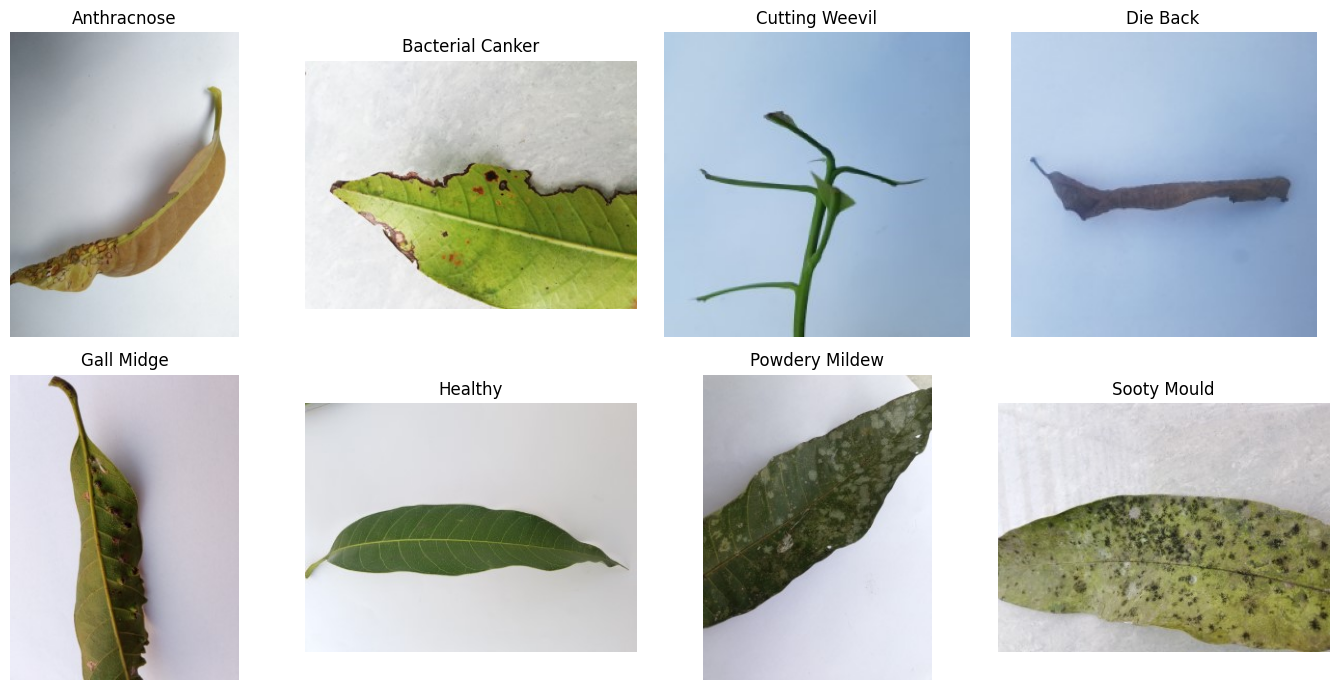

In [15]:

import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, folder in zip(axes.flat, class_dirs):
    image_paths = [
        p for p in folder.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    ]
    img_path = random.choice(image_paths)

    with Image.open(img_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(folder.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:

import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for path in df["path"]:
    with open(path, "rb") as f:
        file_hash = hashlib.md5(f.read()).hexdigest()
    hash_groups[file_hash].append(path)

duplicate_groups = [
    paths for paths in hash_groups.values()
    if len(paths) > 1
]

print("Exact duplicate groups:", len(duplicate_groups))
print("Images involved in exact duplicates:",
      sum(len(paths) for paths in duplicate_groups))


Exact duplicate groups: 21
Images involved in exact duplicates: 42


## 4. Detect likely near-duplicates and create group IDs


In [18]:
%pip -q install ImageHash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 3.4 MB/s eta 0:00:00


In [19]:
import imagehash
from collections import defaultdict

def compute_phash(path):
    try:
        with Image.open(path) as im:
            return imagehash.phash(im.convert("RGB"))
    except Exception:
        return None

t0 = time.time()
hashes = [compute_phash(p) for p in df.path]
df["phash"] = hashes
valid_indices = [i for i, h in enumerate(hashes) if h is not None]
print("Hashes computed:", len(valid_indices), "of", len(df), "in", round(time.time()-t0, 1), "seconds")

# Union-find clustering of images whose pHash Hamming distance <= threshold.
# This pairwise comparison is O(N^2); 4,000 images may take a little time.
parent = list(range(len(df)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

HASH_THRESHOLD = 8
for pos, i in enumerate(valid_indices):
    hi = hashes[i]
    for j in valid_indices[:pos]:
        if hi - hashes[j] <= HASH_THRESHOLD:
            union(i, j)

df["group_id"] = [find(i) if hashes[i] is not None else (len(df)+i) for i in range(len(df))]
print("Estimated unique groups:", df.group_id.nunique())
print("Images grouped beyond singletons:", int((df.groupby("group_id").size() > 1).sum()))
print("Note: inspect duplicate groups and tune threshold cautiously; do not treat this heuristic as perfect ground truth.")

Hashes computed: 4000 of 4000 in 14.7 seconds
Estimated unique groups: 3050
Images grouped beyond singletons: 494
Note: inspect duplicate groups and tune threshold cautiously; do not treat this heuristic as perfect ground truth.


## 5. Group-aware train/validation/test split


In [20]:
# First: 15% test groups
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(gss1.split(df, df.label, groups=df.group_id))
trainval_df = df.iloc[trainval_idx].copy()
test_df = df.iloc[test_idx].copy()

# Then reserve ~15% of total (about 17.65% of remaining) for validation
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=SEED)
train_idx, val_idx = next(gss2.split(trainval_df, trainval_df.label, groups=trainval_df.group_id))
train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

def split_summary(name, part):
    print(f"\n{name}: {len(part)} images, {part.group_id.nunique()} groups")
    print(part.label.value_counts().sort_index())
split_summary("Train", train_df)
split_summary("Validation", val_df)
split_summary("Test", test_df)

# Verify no group crosses splits
train_groups, val_groups, test_groups = set(train_df.group_id), set(val_df.group_id), set(test_df.group_id)
print("\nGroup overlap train/val:", len(train_groups & val_groups))
print("Group overlap train/test:", len(train_groups & test_groups))
print("Group overlap val/test:", len(val_groups & test_groups))
print("Classes missing from any split:",
      {"train": sorted(set(df.label)-set(train_df.label)),
       "val": sorted(set(df.label)-set(val_df.label)),
       "test": sorted(set(df.label)-set(test_df.label))})


Train: 2765 images, 2134 groups
label
Anthracnose         336
Bacterial Canker    334
Cutting Weevil      356
Die Back            329
Gall Midge          354
Healthy             344
Powdery Mildew      351
Sooty Mould         361
Name: count, dtype: int64

Validation: 658 images, 458 groups
label
Anthracnose          78
Bacterial Canker     79
Cutting Weevil       90
Die Back            101
Gall Midge           73
Healthy              89
Powdery Mildew       81
Sooty Mould          67
Name: count, dtype: int64

Test: 577 images, 458 groups
label
Anthracnose         86
Bacterial Canker    87
Cutting Weevil      54
Die Back            70
Gall Midge          73
Healthy             67
Powdery Mildew      68
Sooty Mould         72
Name: count, dtype: int64

Group overlap train/val: 0
Group overlap train/test: 0
Group overlap val/test: 0
Classes missing from any split: {'train': [], 'val': [], 'test': []}


In [21]:

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nClass counts in each split:")
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{split_name}:")
    print(split_df["label"].value_counts().sort_index())


Train images: 2765
Validation images: 658
Test images: 577

Class counts in each split:

Train:
label
Anthracnose         336
Bacterial Canker    334
Cutting Weevil      356
Die Back            329
Gall Midge          354
Healthy             344
Powdery Mildew      351
Sooty Mould         361
Name: count, dtype: int64

Validation:
label
Anthracnose          78
Bacterial Canker     79
Cutting Weevil       90
Die Back            101
Gall Midge           73
Healthy              89
Powdery Mildew       81
Sooty Mould          67
Name: count, dtype: int64

Test:
label
Anthracnose         86
Bacterial Canker    87
Cutting Weevil      54
Die Back            70
Gall Midge          73
Healthy             67
Powdery Mildew      68
Sooty Mould         72
Name: count, dtype: int64


## 6. Build TensorFlow datasets

In [22]:

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

class_names = sorted(df["label"].unique())
label_to_id = {name: i for i, name in enumerate(class_names)}

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(split_df, shuffle=False):
    paths = split_df["path"].values
    labels = split_df["label"].map(label_to_id).values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(
            len(split_df), seed=SEED, reshuffle_each_iteration=True
        )
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Datasets are ready!")
print("Classes:", class_names)


Datasets are ready!
Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']


## 7. Train a compact CNN baseline

In [24]:

EPOCHS = 3

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
], name="augmentation")

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(*IMG_SIZE, 3)),
    augmentation,
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.35),
    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=1,
        restore_best_weights=True
    )
]

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

training_seconds = time.time() - start_time
print("Training time (seconds):", round(training_seconds, 2))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,280 (368.28 KB)

 Trainable params: 94,280 (368.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
87/87 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.2080 - loss: 1.9445 - val_accuracy: 0.4331 - val_loss: 1.5348
Epoch 2/3
87/87 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.4315 - loss: 1.4764 - val_accuracy: 0.5334 - val_loss: 1.1662
Epoch 3/3
87/87 ━━━━━━━━━━━━━━━━━━━━ 178s 2s/step - accuracy: 0.5515 - loss: 1.2179 - val_accuracy: 0.7477 - val_loss: 0.8482
Training time (seconds): 576.6


In [26]:

print("Model exists:", "model" in globals())
print("Training history exists:", "history" in globals())
print("Test dataset exists:", "test_ds" in globals())
print("Test split exists:", "test_df" in globals())
print("Class names exist:", "class_names" in globals())


Model exists: True
Training history exists: True
Test dataset exists: True
Test split exists: True
Class names exist: True


In [ ]:

import tensorflow as tf
import pandas as pd

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

label_to_id = {name: i for i, name in enumerate(class_names)}

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

paths = test_df["path"].values
labels = test_df["label"].map(label_to_id).values

test_ds = tf.data.Dataset.from_tensor_slices((paths, labels))
test_ds = test_ds.map(
    load_image, num_parallel_calls=tf.data.AUTOTUNE
)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Test dataset recreated:", len(test_df), "images")


## 8. Plot training and validation accuracy/loss

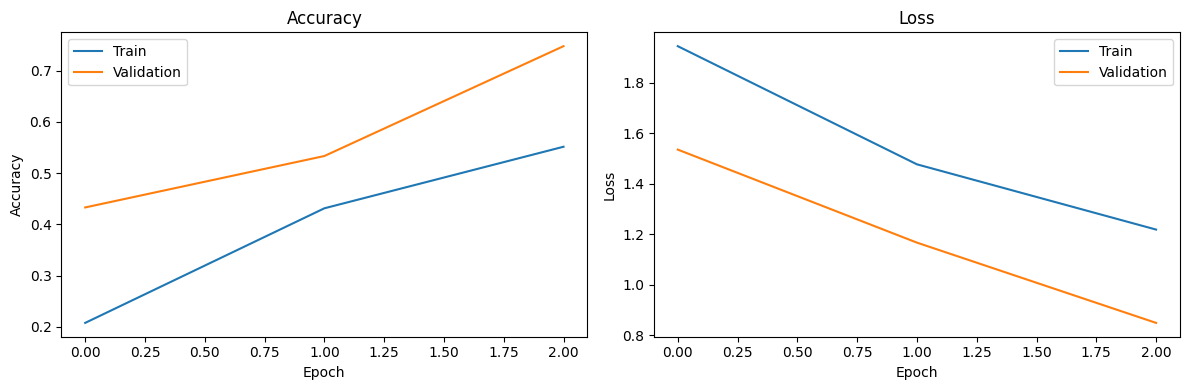

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Evaluate once on the held-out test set

Test accuracy: 70.02%
Test macro F1: 0.7038

Per-class precision, recall and F1:
                  precision    recall  f1-score   support

     Anthracnose     0.8308    0.6279    0.7152        86
Bacterial Canker     0.6383    0.6897    0.6630        87
  Cutting Weevil     0.9583    0.8519    0.9020        54
        Die Back     0.7013    0.7714    0.7347        70
      Gall Midge     0.6066    0.5068    0.5522        73
         Healthy     0.7821    0.9104    0.8414        67
  Powdery Mildew     0.6000    0.8824    0.7143        68
     Sooty Mould     0.5926    0.4444    0.5079        72

        accuracy                         0.7002       577
       macro avg     0.7137    0.7106    0.7038       577
    weighted avg     0.7070    0.7002    0.6952       577



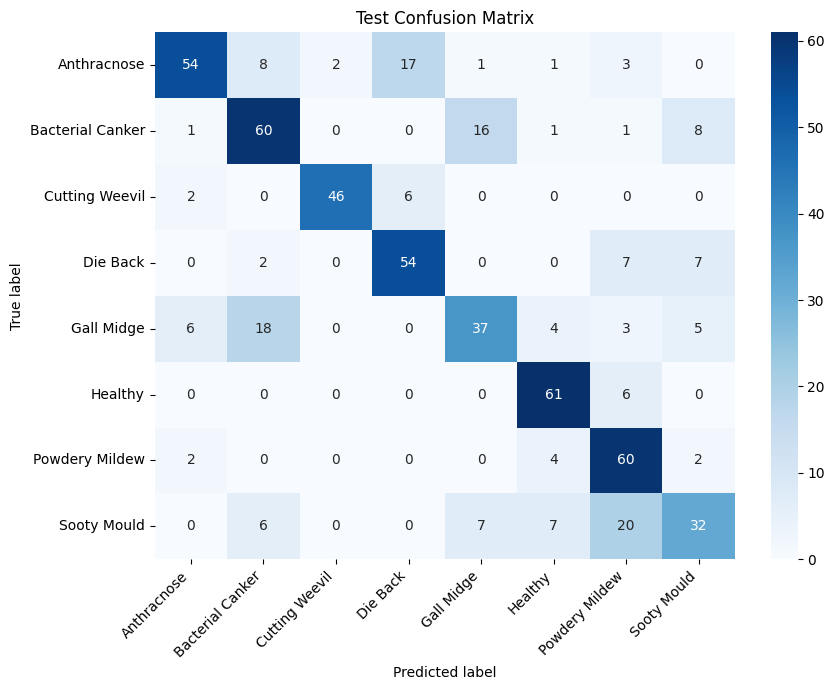

In [28]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

test_accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
print(f"Test accuracy: {test_accuracy*100:.2f}%")
print(f"Test macro F1: {macro_f1:.4f}")
print("\nPer-class precision, recall and F1:")
print(classification_report(
    y_true, y_pred, labels=list(range(len(class_names))),
    target_names=class_names, digits=4, zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title("Test Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

## 10. Display at least four misclassified test images

Misclassified test images: 173


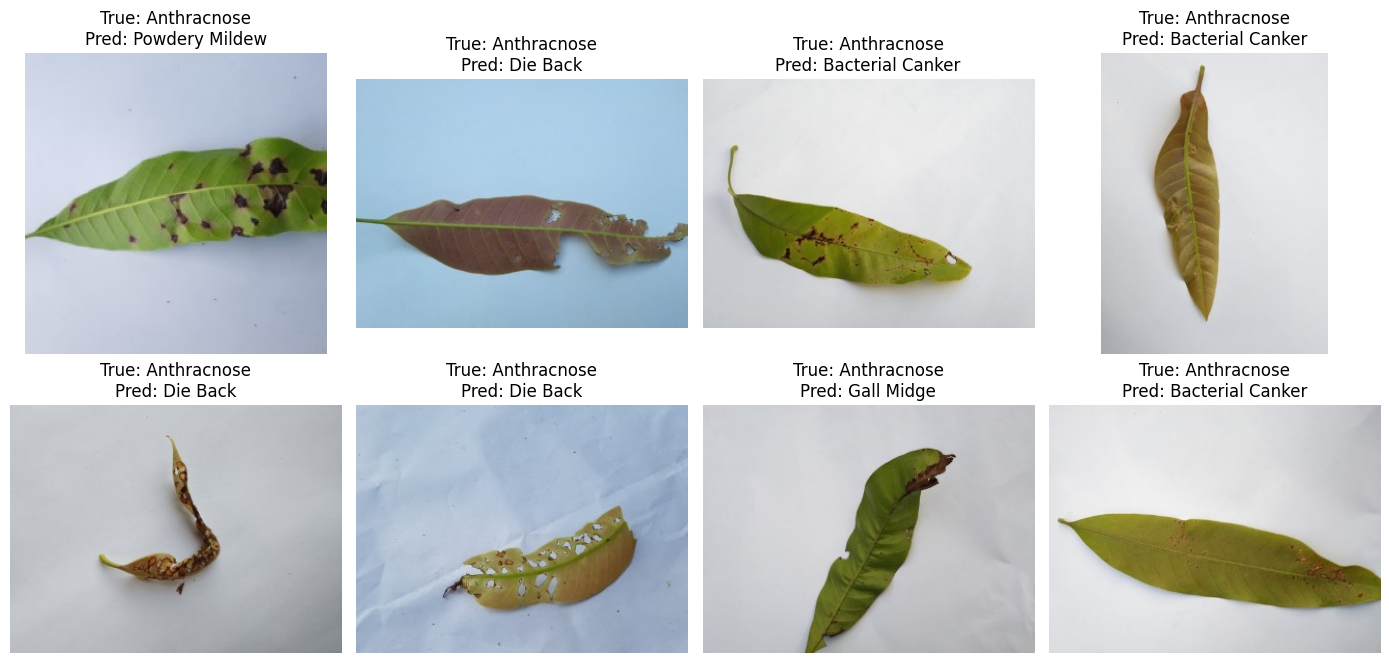

Discuss only observed examples. Possible causes include similar symptoms, lighting, blur, leaf angle, background, or label ambiguity.


In [29]:
test_paths = test_df.path.to_numpy()
errors = np.where(y_true != y_pred)[0]
print("Misclassified test images:", len(errors))

if len(errors) == 0:
    print("No errors in this test split. Report this honestly; do not fabricate examples.")
else:
    chosen = errors[:min(8, len(errors))]
    cols = 4
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 3.5 * rows))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, idx in zip(axes, chosen):
        im = Image.open(test_paths[idx]).convert("RGB")
        ax.imshow(im)
        ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}")
        ax.axis("off")
    plt.tight_layout(); plt.show()

print("Discuss only observed examples. Possible causes include similar symptoms, lighting, blur, leaf angle, background, or label ambiguity.")

## 11. Save model and notebook evidence

In [30]:
model.save("PS03_MangoLeaf_CNN.keras")
print("Saved model as PS03_MangoLeaf_CNN.keras")
print("Remember to save/export this notebook with all outputs as RegisterNo_PS03.ipynb.")
print("Record the actual test metrics, split sizes, class counts, estimated duplicate-group method, and limitations in the report.")

Saved model as PS03_MangoLeaf_CNN.keras
Remember to save/export this notebook with all outputs as RegisterNo_PS03.ipynb.
Record the actual test metrics, split sizes, class counts, estimated duplicate-group method, and limitations in the report.
